In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt 

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [5]:
# select only digit 0 for training 
x_train = x_train[y_train==0]

In [6]:
# normalize data
x_train = x_train/255.0
x_test = x_test/255.0

In [7]:
#flatten images
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

In [8]:
#build model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    #encoder
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    
    #decoder
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(784, activation='sigmoid'),
])

In [9]:
#compile the model 
model.compile(
    optimizer = 'adam',
    loss = 'mse'
)

In [10]:
#train the model 
model.fit(x_train, x_train, epochs=10, batch_size=32)

Epoch 1/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0753
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0418
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0352
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0299
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0268
Epoch 6/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0243
Epoch 7/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0224
Epoch 8/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0209
Epoch 9/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0199
Epoch 10/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0192


In [11]:
#predict the output
prediction = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [12]:
# calculating the error
error = np.mean((x_test - prediction) ** 2, axis=1)

In [13]:
#set threshold 
threshold = np.percentile(error, 95)

In [14]:
#detect anomalies
anomalies = error > threshold
print('Anomalies : ', sum(anomalies))
print('Normal Records : ', sum(~anomalies))

Anomalies :  500
Normal Records :  9500


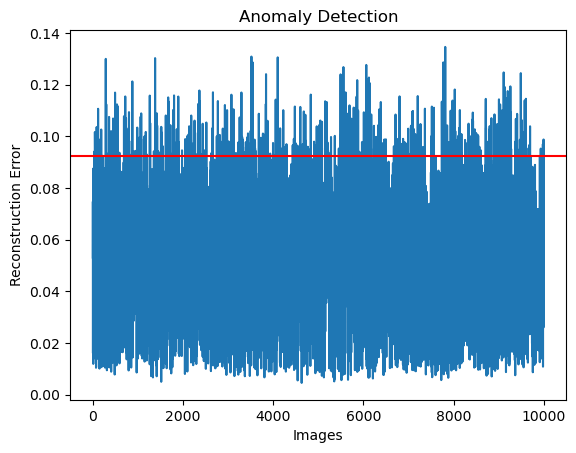

In [15]:
#display draph 
plt.plot(error)
plt.axhline(threshold, color='red')
plt.title('Anomaly Detection')
plt.xlabel('Images')
plt.ylabel('Reconstruction Error')
plt.show()

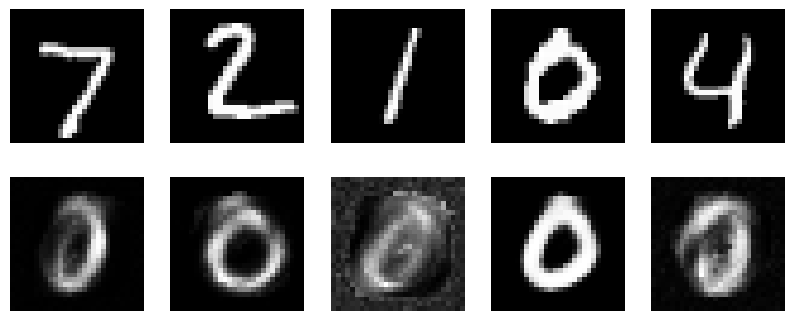

In [17]:
#displaying original and reconstructed image 
prediction = prediction.reshape(-1, 28, 28)
plt.figure(figsize=(10,4))
for i in range(5) :
    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    plt.subplot(2, 5, i+6)
    plt.imshow(prediction[i], cmap='gray')
    plt.axis('off')

plt.show()